# Le projet, en une page

Refonte du cours PROJ0016, « Big Data Project 2020 – COVID-20 » (Gilles Louppe, ULiège).

Une ville fictive d'un million d'habitants est observée jour après jour. Le jour 1 est le 2 octobre 2020. Le jour 122 est le 31 janvier 2021. On ne reçoit pas le nombre d'infectés. On reçoit des comptages : tests, cas confirmés, lits occupés, décès.

Le travail tient en trois temps :

1. estimer un modèle SEIR bayésien à partir de ces comptages ;
2. projeter plusieurs futurs, parce qu'une probabilité n'existe que si plusieurs trajectoires restent possibles ;
3. recommander l'intervention la moins contraignante qui garde les hospitalisés sous 1 500 et les soins intensifs sous 300.

Ces quatre notebooks ne refont pas le calcul. Ils appellent le paquet `epidemic` (`src/epidemic/`) et montrent ce qu'il fait.

| Notebook | Question |
|---|---|
| celui-ci | Que reçoit-on, et que doit-on décider ? |
| `guide_01_la_ville.ipynb` | Comment la ville cachée produit ces chiffres ? |
| `guide_02_le_modele.ipynb` | Que voit le modèle, et qu'est-ce qu'il suppose ? |
| `guide_03_la_decision.ipynb` | Comment passe-t-on d'une probabilité à une mesure ? |

Les autres fichiers de ce dossier (`1.ipynb`, `cleaning.ipynb`, `model_definition.ipynb`, `02_infer_parameters.ipynb`, …) datent de l'exploration de 2020. Ils importent `src/build_model_numpyro.py`. Ce n'est pas le code de la refonte. Le dossier `old/` non plus.

Ouvrir ces notebooks avec l'environnement du dépôt (`.venv`, après `uv sync`).


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook est dans notebooks/. On remonte à la racine du dépôt.
RACINE = Path.cwd().resolve()
if not (RACINE / "pyproject.toml").exists():
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE / "src"))

%matplotlib inline
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)


## Ce que l'on publie chaque jour

Le fichier du cours est `data/external/data.csv` : 71 jours réellement distribués pendant le projet. Les noms de colonnes sont ceux du fichier, y compris l'orthographe `num_hospitalised`.


In [2]:
cours = pd.read_csv(RACINE / "data" / "external" / "data.csv")
print(f"{len(cours)} jours, colonnes : {list(cours.columns)}")
print()
print(cours.head(3).to_string(index=False))
print()
dernier = cours.iloc[-1]
print(
    f"Dernier jour publié : {int(dernier['Day'])}. "
    f"Cas du jour : {int(dernier['num_positive'])}. "
    f"Hospitalisés : {int(dernier['num_hospitalised'])}. "
    f"Soins intensifs : {int(dernier['num_critical'])}. "
    f"Décès cumulés : {int(dernier['num_fatalities'])}."
)


71 jours, colonnes : ['Day', 'num_positive', 'num_tested', 'num_hospitalised', 'num_cumulative_hospitalizations', 'num_critical', 'num_fatalities']

 Day  num_positive  num_tested  num_hospitalised  num_cumulative_hospitalizations  num_critical  num_fatalities
   1             0           0                 1                                1             0               0
   2             5           8                 1                                1             0               0
   3            10          12                 2                                2             0               0

Dernier jour publié : 71. Cas du jour : 2035. Hospitalisés : 774. Soins intensifs : 76. Décès cumulés : 43.


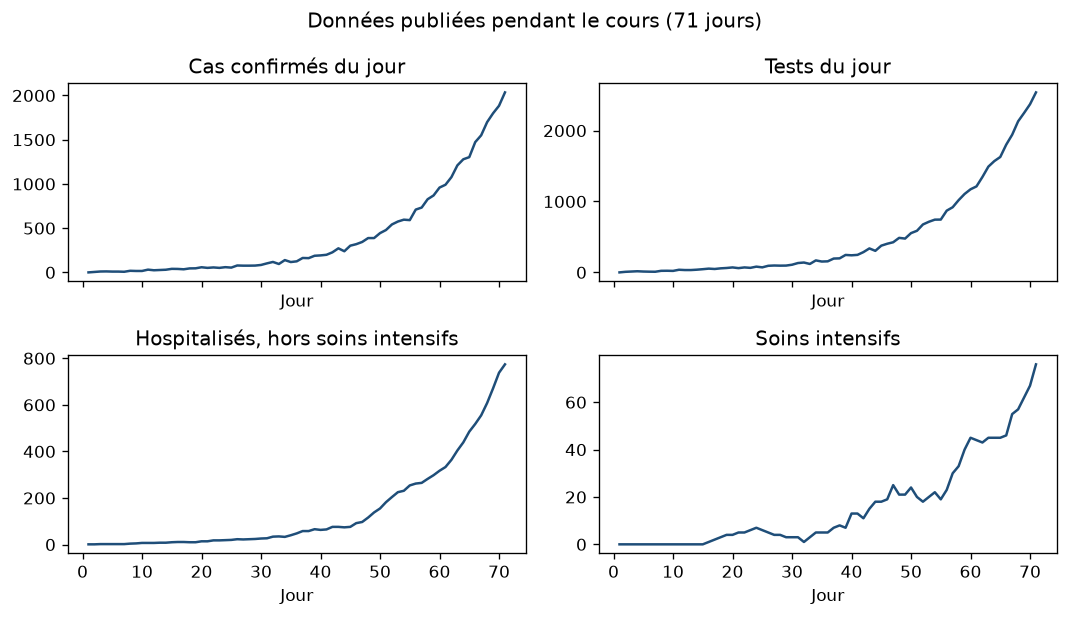

In [3]:
panneaux = [
    ("num_positive", "Cas confirmés du jour"),
    ("num_tested", "Tests du jour"),
    ("num_hospitalised", "Hospitalisés, hors soins intensifs"),
    ("num_critical", "Soins intensifs"),
]
figure, axes = plt.subplots(2, 2, figsize=(9, 5.2), sharex=True)
for axe, (colonne, titre) in zip(axes.ravel(), panneaux, strict=True):
    axe.plot(cours["Day"], cours[colonne], color="#1f4e79")
    axe.set_title(titre)
    axe.set_xlabel("Jour")
figure.suptitle("Données publiées pendant le cours (71 jours)")
figure.tight_layout()


Deux lectures utiles de ce graphique.

Les cas confirmés ne sont pas les infections. Une personne peut être contagieuse sans symptôme, un symptomatique n'est pas toujours testé, et un test rate 15 à 30 % des infectés (sensibilité 70 à 85 %). Les deux courbes du bas sont des stocks : des lits occupés ce jour-là, pas des entrées.

`num_cumulative_hospitalizations` et `num_fatalities` sont des cumuls. Le modèle d'inférence transforme les décès cumulés en décès du jour. On le verra dans le notebook du modèle.


## Ce qu'il faut décider

Rester sous les deux plafonds jusqu'au 31 janvier, avec la mesure la moins contraignante. « Moins contraignante » est un coût choisi dans le projet, pas une consigne du cours : le masque coûte 1 par jour, le confinement 8. Les coûts s'additionnent. Les effets sur les contacts, eux, ne s'additionnent pas : c'est la réduction la plus forte qui s'applique, puis le masque multiplie le taux d'infection.


In [4]:
from epidemic.config import load_game_config, load_thresholds_config

plafonds = load_thresholds_config()
jeu = load_game_config()
print(f"Hospitalisés < {plafonds.max_hospitalized}")
print(f"Soins intensifs < {plafonds.max_critical}")
print(f"Jusqu'au jour {jeu.end_day} ({plafonds.horizon_end})")
print()
print("Coût d'une journée avec la mesure :")
for nom, cout in jeu.constraint_costs.items():
    print(f"  {nom:24} {int(cout)}")


Hospitalisés < 1500
Soins intensifs < 300
Jusqu'au jour 122 (2021-01-31)

Coût d'une journée avec la mesure :
  mask                     1
  case_isolation           2
  social_distancing        3
  household_quarantine     4
  lockdown                 8


Le seuil de décision est une probabilité : on garde le paquet le moins coûteux dont la probabilité de saturation reste d'au plus 5 %. Cette probabilité sort de la loi a posteriori. Sans ajustement, on n'a pas le droit de l'inventer. Le notebook de la décision montre la règle sur un exemple chiffré, puis dit où le calcul réel est branché.

Les mesures n'arrivent pas toutes le premier jour. Le palier 1 (jour 21) ouvre le masque et l'isolement. Le palier 2 (jour 42) ajoute la quarantaine du ménage et la distanciation. Le palier 3 (jour 63) ajoute le confinement. Une décision met 3 jours à prendre effet, et une mesure reste au moins 14 jours.


## Où est le code

| Dossier | Rôle |
|---|---|
| `src/epidemic/simulator` | La ville. Paramètres cachés, contacts, hasard, interventions. |
| `src/epidemic/model` | Le SEIRH bayésien. Il ne lit que les observations. |
| `src/epidemic/inference` | Ajustement NUTS ou SVI, diagnostics. |
| `src/epidemic/forecast` | Projections et probabilités de saturation. |
| `src/epidemic/decision` | Comparaison des paquets et recommandation. |
| `src/epidemic/viz` | Graphiques. |
| `src/epidemic/reporting` | Bulletin, rapport, diapositives. Les chiffres du texte sont calculés, pas saisis. |
| `configs/` | YAML : simulateur, priors, inférence, jeu, décision. |
| `app/` | Streamlit. Jouer avance la ville. Analyser charge un CSV. |
| `data/external/` | `data.csv` et les statistiques de la ville. |
| `docs/hypotheses.md` | Tout ce qui n'est pas fixé par les consignes. |

La ligne de commande reprend les mêmes étapes : `uv run epidemic simulate`, `fit`, `bulletin`, `report`. L'application : `uv run streamlit run app/accueil.py`.


In [5]:
import importlib
import pkgutil

import epidemic

# Liste les sous-paquets et la première ligne de leur docstring.
for module in pkgutil.iter_modules(epidemic.__path__):
    if not module.ispkg:
        continue
    charge = importlib.import_module(f"epidemic.{module.name}")
    premiere = (charge.__doc__ or "").splitlines()[0]
    print(f"{module.name:12} {premiere}")


decision     Comparaison des interventions et recommandation.
forecast     Projections, scénarios et probabilités de saturation.
inference    MCMC, SVI et diagnostics.
model        Modèle SEIRH bayésien. Il ne voit que les observations.
reporting    Rapport, documentation générée et bulletins.
simulator    Simulateur stochastique : la réalité cachée du jeu.
viz          Graphiques du bulletin, de l'application et du rapport.
